# Originación: mezcla de cartera, tasas y contracción

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Grupos simulados:** 80
- **Cambios inyectados:** 4
- **Grupos revisados por criterio:** 8
- **Mayor residuo ajustado:** 9.7
- **rho beta-binomial ajustado:** 0.0572
- **NLL beta-binomial test:** 3.2774
- **NLL binomial test:** 4.8174

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Un canal tiene más omisiones o simplemente atiende una población distinta? Comparamos tasas brutas, esperadas según mezcla y contracción hacia una referencia conocida.

### Supuestos y población

Eventos de omisión de control simulados en 80 grupos, no etiquetas de fraude. Dos productos con tasas base diferentes. Las probabilidades de referencia son conocidas por el simulador y no se estiman con el mismo resultado a evaluar.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. El denominador y la mezcla cambian la tasa


$$E_g=\sum_i p_{ig}^{ref},\quad O_g=\sum_i y_{ig},\quad z_g=\frac{O_g-E_g}{\sqrt{\sum_i p_{ig}^{ref}(1-p_{ig}^{ref})}}.$$

La varianza supone independencia condicional. En lotes dependientes o sobredispersión puede subestimar incertidumbre; no se usa como prueba universal de fraude.

,grupo,n,mezcla_alta,O,E,tasa_bruta,tasa_esperada,z,anomalia_simulada
28,28,17,0.9412,4,2.4250,0.2353,0.1426,1.0962,False
33,33,263,0.3384,56,17.7000,0.2129,0.0673,9.7005,True
52,52,33,0.4848,7,2.8250,0.2121,0.0856,2.6649,True
10,10,24,0.4583,5,1.9750,0.2083,0.0823,2.3070,False
41,41,10,0.7000,2,1.1250,0.2000,0.1125,0.8904,False
60,60,74,0.8108,14,9.3500,0.1892,0.1264,1.6449,False
40,40,11,0.8182,2,1.4000,0.1818,0.1273,0.5486,False
7,7,45,0.0000,8,1.1250,0.1778,0.0250,6.5644,True


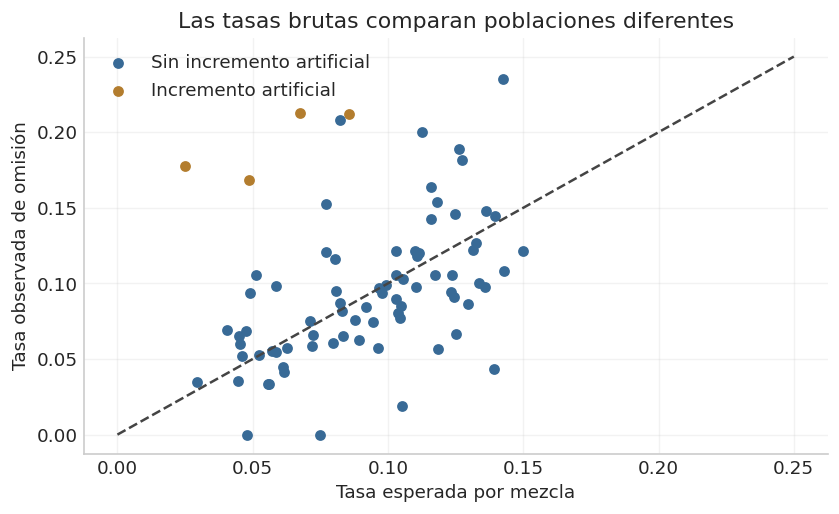

In [2]:
groups=80
volumes=rng.integers(8,300,groups)
mixture=rng.beta(1.5,1.5,groups)
anomalous=np.zeros(groups,dtype=bool);anomalous[[7,18,33,52]]=True
records=[]
for g in range(groups):
    high=rng.binomial(1,mixture[g],volumes[g])
    reference=np.where(high==1,.15,.025)
    actual=np.minimum(1,reference+.13*anomalous[g])
    observed=rng.binomial(1,actual).sum()
    expected=reference.sum();variance=np.sum(reference*(1-reference))
    records.append({'grupo':g,'n':volumes[g],'mezcla_alta':high.mean(),'O':observed,'E':expected,
                    'tasa_bruta':observed/volumes[g],'tasa_esperada':expected/volumes[g],
                    'z':(observed-expected)/np.sqrt(variance),'anomalia_simulada':anomalous[g]})
process=pd.DataFrame(records)
display(process.sort_values('tasa_bruta',ascending=False).head(8))
fig,ax=plt.subplots()
for flag,color,label in [(False,BLUE,'Sin incremento artificial'),(True,GOLD,'Incremento artificial')]:
    subset=process[process['anomalia_simulada']==flag]
    ax.scatter(subset['tasa_esperada'],subset['tasa_bruta'],color=color,label=label,s=30)
ax.plot([0,.25],[0,.25],color='#444444',linestyle='--')
ax.set(xlabel='Tasa esperada por mezcla',ylabel='Tasa observada de omisión',title='Las tasas brutas comparan poblaciones diferentes');ax.legend();plt.show()

Las cuatro anomalías se inyectan por construcción. Un punto sobre la diagonal puede aparecer por azar, una política nueva o un problema de registro. El gráfico compara un evento de control, no prueba intención ni fraude.

## 2. Contracción explícita de grupos pequeños


Con una referencia $p_g^{ref}=E_g/n_g$ y fuerza previa $\tau$, una media regularizada es
$$\tilde p_g=\frac{O_g+\tau p_g^{ref}}{n_g+\tau}.$$

Aquí es una regla de contracción motivada por beta-binomial. No es un modelo jerárquico completo: ni $\tau$ ni la referencia se estiman de forma bayesiana en este notebook.

,grupo,n,tasa_bruta,tasa_esperada,tasa_contraida,z,anomalia_simulada
33,33,263,0.2129,0.0673,0.1937,9.7005,True
18,18,190,0.1684,0.0487,0.1476,7.8759,True
7,7,45,0.1778,0.0250,0.1059,6.5644,True
2,2,235,0.0936,0.0489,0.0871,3.2608,False
52,52,33,0.2121,0.0856,0.1428,2.6649,True
17,17,72,0.1528,0.0771,0.1257,2.4750,False
10,10,24,0.2083,0.0823,0.1296,2.3070,False
63,63,259,0.1158,0.0805,0.1111,2.1464,False
60,60,74,0.1892,0.1264,0.1671,1.6449,False
11,11,91,0.1209,0.0772,0.1075,1.6046,False


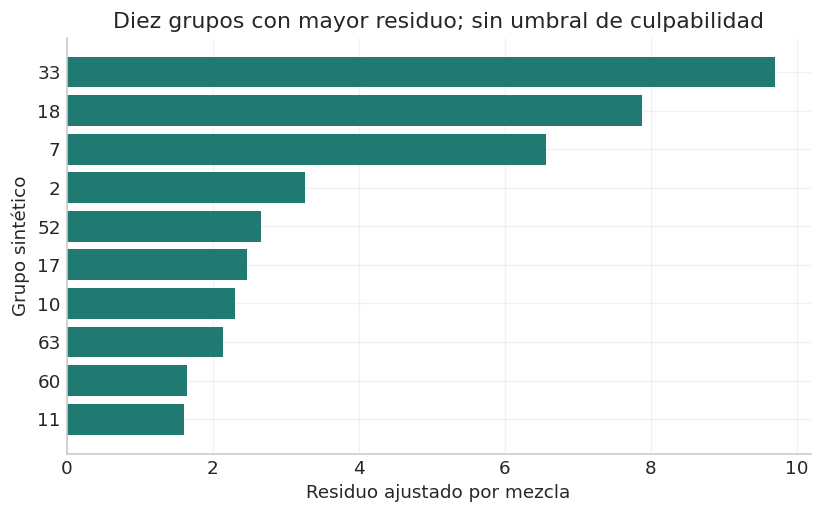

In [3]:
tau=40.
process['tasa_contraida']=(process['O']+tau*process['tasa_esperada'])/(process['n']+tau)
process['exceso_contraido']=process['tasa_contraida']-process['tasa_esperada']
ranked=process.sort_values('z',ascending=False).head(10)
display(ranked[['grupo','n','tasa_bruta','tasa_esperada','tasa_contraida','z','anomalia_simulada']])
fig,ax=plt.subplots();ax.barh(ranked['grupo'].astype(str),ranked['z'],color=TEAL)
ax.invert_yaxis();ax.set(xlabel='Residuo ajustado por mezcla',ylabel='Grupo sintético',title='Diez grupos con mayor residuo; sin umbral de culpabilidad');plt.show()

El ranking ofrece una prioridad de investigación, no significancia corregida por probar 80 grupos. Una contracción fuerte puede ocultar cambios reales en grupos pequeños; debe contrastarse con demora y carga de casos.

## 3. Sensibilidad a la fuerza de la referencia


Para $\tau\to0$ se recupera la tasa bruta; para $\tau\to\infty$ la referencia domina. Contar anomalías inyectadas entre los primeros K sirve como diagnóstico del simulador, no como recall de fraude real.

In [4]:
comparison=[]
K=8
for score in ['tasa_bruta','z','exceso_contraido']:
    selected=process.nlargest(K,score)
    comparison.append({'criterio':score,'K':K,'cambios_inyectados_en_K':int(selected['anomalia_simulada'].sum()),'volumen_medio':selected['n'].mean()})
display(pd.DataFrame(comparison))
small=process.nsmallest(1,'n').iloc[0]
tau_table=pd.DataFrame({'tau':[0,10,40,100,1000]})
tau_table['tasa_contraida']=(small['O']+tau_table['tau']*small['tasa_esperada'])/(small['n']+tau_table['tau'])
display(tau_table)

,criterio,K,cambios_inyectados_en_K,volumen_medio
0,tasa_bruta,8,3,59.6250
1,z,8,4,140.1250
2,exceso_contraido,8,4,117.0000


,tau,tasa_contraida
0,0,0.2000
1,10,0.1562
2,40,0.1300
3,100,0.1205
4,1000,0.1134


No elegimos tau con el conteo de anomalías de este test. Una extensión debe separar entrenamiento y validación, estimar la mezcla sin fuga y considerar correlación dentro del canal y a través del tiempo.

## Desarrollo ampliado: modelo, estimación y uso


**Uso:** priorizar investigación de omisiones de control por canal, comercio o equipo. **Entrada:** denominadores por producto, versión de política y eventos maduros. **Salida:** exceso ajustado e incertidumbre; no una acusación de fraude interno.

Se distinguen mezcla, dispersión entre grupos y variación temporal. El modelo de referencia anterior es conocido por el generador. Ahora se ajusta un modelo beta-binomial a un conjunto de entrenamiento separado y se contrasta con un baseline binomial sobre grupos posteriores.

In [5]:
advanced_metrics = {}
advanced_rng = np.random.default_rng(9221)

### 4. De binomial a beta-binomial


Si $p_g\sim Beta(a,b)$ y $O_g\mid p_g\sim Binomial(n_g,p_g)$:
$$E[p_g]=\mu=\frac a{a+b},\quad\rho=\frac1{a+b+1},$$
$$E[O_g]=n_g\mu,\quad Var(O_g)=n_g\mu(1-\mu)[1+(n_g-1)\rho].$$

La verosimilitud marginal es $\binom nO B(O+a,n-O+b)/B(a,b)$. No aplica sin ajuste a grupos con mezclas de producto diferentes; el experimento usa una referencia homogénea independiente del anterior.

In [6]:
from scipy.special import betaln,gammaln
from scipy.optimize import minimize
from scipy.stats import betabinom,binom,beta
bb_n=100
bb_p_train=advanced_rng.beta(2.,18.,250)
bb_o_train=advanced_rng.binomial(bb_n,bb_p_train)
bb_p_test=advanced_rng.beta(2.,18.,180)
bb_o_test=advanced_rng.binomial(bb_n,bb_p_test)
def bb_negative_log_likelihood(log_ab):
    a,b=np.exp(log_ab)
    log_choose=gammaln(bb_n+1)-gammaln(bb_o_train+1)-gammaln(bb_n-bb_o_train+1)
    return -float(np.sum(log_choose+betaln(bb_o_train+a,bb_n-bb_o_train+b)-betaln(a,b)))
bb_fit=minimize(bb_negative_log_likelihood,np.log([2.,18.]),method='L-BFGS-B',bounds=[(-5,8),(-5,8)])
assert bb_fit.success
a_hat,b_hat=np.exp(bb_fit.x);mu_hat=a_hat/(a_hat+b_hat);rho_hat=1/(a_hat+b_hat+1)
display(pd.DataFrame({'parametro':['a','b','mu','rho'],'estimado':[a_hat,b_hat,mu_hat,rho_hat],'verdad_sintetica':[2,18,.1,1/21]}))

,parametro,estimado,verdad_sintetica
0,a,1.7687,2.0000
1,b,14.7260,18.0000
2,mu,0.1072,0.1000
3,rho,0.0572,0.0476


**Interpretación y uso.** El ajuste aprende hiperparámetros en 250 grupos, no en los grupos evaluados. La beta-binomial capta heterogeneidad de tasas bajo su supuesto, no distingue por qué varían ni identifica fraude.

### 5. Comparación predictiva en grupos no usados en ajuste


La densidad predictiva se evalúa con log score: $-m^{-1}\sum_g\log P(O_g\mid n_g)$. Se comparan binomial con media estimada y beta-binomial con hiperparámetros estimados. Ambos usan el mismo entrenamiento y n.

,modelo,NLL_promedio
0,Binomial,4.8174
1,Beta-binomial,3.2774


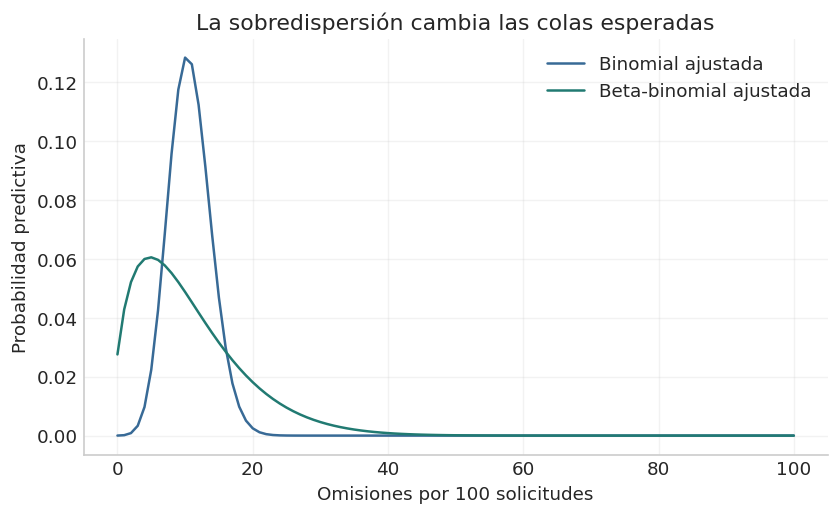

In [7]:
mu_bin=bb_o_train.sum()/(len(bb_o_train)*bb_n)
bin_ll=binom.logpmf(bb_o_test,bb_n,mu_bin)
bb_ll=betabinom.logpmf(bb_o_test,bb_n,a_hat,b_hat)
predictive_scores=pd.DataFrame({'modelo':['Binomial','Beta-binomial'],'NLL_promedio':[-bin_ll.mean(),-bb_ll.mean()]})
display(predictive_scores)
counts=np.arange(bb_n+1)
fig,ax=plt.subplots();ax.plot(counts,binom.pmf(counts,bb_n,mu_bin),color=BLUE,label='Binomial ajustada')
ax.plot(counts,betabinom.pmf(counts,bb_n,a_hat,b_hat),color=TEAL,label='Beta-binomial ajustada')
ax.set(xlabel='Omisiones por 100 solicitudes',ylabel='Probabilidad predictiva',title='La sobredispersión cambia las colas esperadas');ax.legend();plt.show()
assert np.isclose(betabinom.pmf(counts,bb_n,a_hat,b_hat).sum(),1)

**Interpretación y uso.** Si se usa una binomial demasiado estrecha pueden aparecer falsas anomalías. Un modelo disperso también puede ocultar un cambio real: evaluar únicamente log score no determina la política de alertas.

### 6. Actualización de una tasa por grupo


Con hiperparámetros ya ajustados y un nuevo grupo observado:
$$p_g\mid O_g\sim Beta(a+O_g,b+n_g-O_g).$$

La media posterior contrae la tasa y sus cuantiles resumen incertidumbre condicional al prior ajustado. La inferencia empirical Bayes no incluye incertidumbre de los hiperparámetros; debe decirse explícitamente.

,O,n,tasa_bruta,media_posterior,low95,high95
0,0,100,0.0000,0.0152,0.0015,0.0439
1,5,100,0.0500,0.0581,0.0234,0.1070
2,15,100,0.1500,0.1439,0.0866,0.2129
3,30,100,0.3000,0.2727,0.1961,0.3567


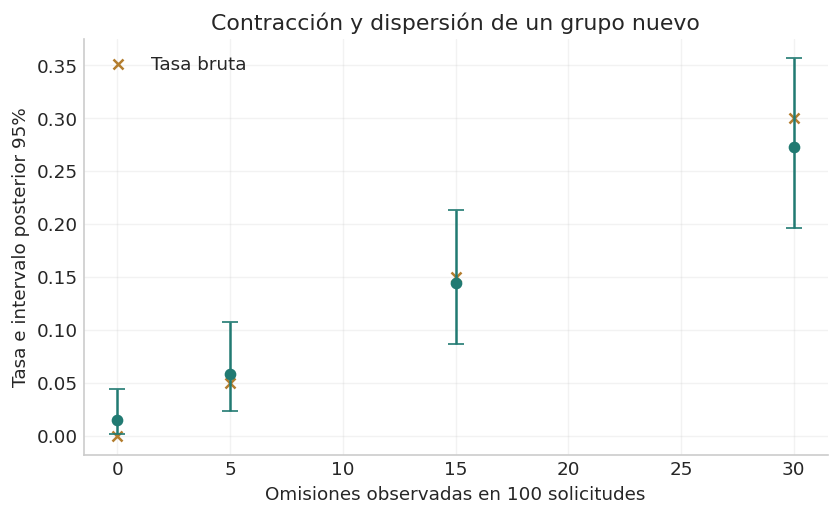

In [8]:
posterior_rows=[]
for observed in [0,5,15,30]:
    aa,bb=a_hat+observed,b_hat+bb_n-observed
    posterior_rows.append({'O':observed,'n':bb_n,'tasa_bruta':observed/bb_n,'media_posterior':aa/(aa+bb),'low95':beta.ppf(.025,aa,bb),'high95':beta.ppf(.975,aa,bb)})
posterior_rows=pd.DataFrame(posterior_rows);display(posterior_rows)
fig,ax=plt.subplots();ax.errorbar(posterior_rows['O'],posterior_rows['media_posterior'],yerr=[posterior_rows['media_posterior']-posterior_rows['low95'],posterior_rows['high95']-posterior_rows['media_posterior']],fmt='o',color=TEAL,capsize=5)
ax.scatter(posterior_rows['O'],posterior_rows['tasa_bruta'],marker='x',color=GOLD,label='Tasa bruta')
ax.set(xlabel='Omisiones observadas en 100 solicitudes',ylabel='Tasa e intervalo posterior 95%',title='Contracción y dispersión de un grupo nuevo');ax.legend();plt.show()

**Interpretación y uso.** Estos intervalos no son p-valores ni evidencia de conducta indebida. Para comparar grupos con productos diferentes hay que ajustar la media de referencia por mezcla antes de interpretar el exceso.

### 7. Alarmas predictivas y alcance de la evaluación


Una cola superior de referencia es $P(O\ge O_{obs})$. Se compara la fracción de grupos de prueba con cola menor que 1% bajo ambas referencias. La distribución es discreta y el ajuste es estimado; no se exige exactamente 1%.

In [9]:
bin_tail=binom.sf(bb_o_test-1,bb_n,mu_bin)
bb_tail=betabinom.sf(bb_o_test-1,bb_n,a_hat,b_hat)
display(pd.DataFrame({'referencia':['Binomial','Beta-binomial'],'fraccion_grupos_en_cola_1pct':[np.mean(bin_tail<.01),np.mean(bb_tail<.01)],'grupos_test':[len(bb_o_test)]*2}))
assert np.isfinite(bb_tail).all()
advanced_metrics.update({'rho beta-binomial ajustado':round(float(rho_hat),4),'NLL beta-binomial test':round(float(-bb_ll.mean()),4),'NLL binomial test':round(float(-bin_ll.mean()),4)})

,referencia,fraccion_grupos_en_cola_1pct,grupos_test
0,Binomial,0.1500,180
1,Beta-binomial,0.0000,180


**Interpretación y uso.** La comparación usa grupos generados por beta-binomial, lo que favorece al modelo correctamente especificado. Conservar el resultado como recuperación de un mecanismo conocido, no como ganador universal; probar cambios de mezcla y lotes dependientes antes de promoverlo.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [10]:
assert ((process['tasa_contraida']>=process[['tasa_bruta','tasa_esperada']].min(axis=1)-1e-12)&(process['tasa_contraida']<=process[['tasa_bruta','tasa_esperada']].max(axis=1)+1e-12)).all()
assert process['n'].min()>0
assert np.isfinite(process['z']).all()

## Resultados computados

In [11]:
metrics = {'Grupos simulados': groups, 'Cambios inyectados': int(anomalous.sum()), 'Grupos revisados por criterio': K, 'Mayor residuo ajustado': round(float(process['z'].max()),3)}
metrics.update(advanced_metrics)
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Grupos simulados": 80, "Cambios inyectados": 4, "Grupos revisados por criterio": 8, "Mayor residuo ajustado": 9.7, "rho beta-binomial ajustado": 0.0572, "NLL beta-binomial test": 3.2774, "NLL binomial test": 4.8174}


## Ideas y preguntas para continuar

1. Estimar tasas base por producto en una ventana histórica cerrada.
2. Ajustar sobredispersión y dependencia por lotes antes de usar p-valores.
3. Comparar contracción con modelo jerárquico de efectos de grupo.
4. Incluir versión de política y cambios de logging como explicaciones alternativas.
5. Diseñar un presupuesto de alertas y criterios de escalamiento, no acusaciones automáticas.

## Fuentes y relación con el proyecto

La referencia y las anomalías se conocen solo por construcción del simulador. La contracción es una identidad algebraica explícita; no se presenta como un modelo bayesiano estimado. Proyecto: `../README.md`.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.

## Uso responsable y ficha mínima de salida

Antes de una aplicación institucional, registrar población, corte de información, versión del modelo, horizonte, unidades y cobertura de fuentes. Separar score de anomalía, probabilidad estimada y costo por acción. Una discrepancia o un desvío requiere evidencia independiente antes de llamarlo fraude. El experimento está completo en su alcance sintético; no sustituye calibración externa, integración de datos o validación independiente.

## Preguntas para refutar el desarrollo

1. ¿La mejora persiste al cambiar el mecanismo generador y la cohorte?
2. ¿Qué variable solo estaría disponible después de decidir?
3. ¿Cuánto del beneficio depende de una eficacia o cobertura supuesta?
4. ¿Qué caso legítimo produce la misma señal?
5. ¿Puede otra persona reconstruir el resultado desde las celdas y los parámetros?

## Diccionario de símbolos y unidades

| Símbolo | Significado en este notebook | Unidad o restricción |
|---|---|---|
| n, O, E | Exposición, eventos y expectativa | Conteos con denominador explícito |
| z | Residuo frente a mezcla de referencia | No es p-valor universal |
| τ | Fuerza de contracción inicial | Pseudoconteo fijado, no ajustado |
| a, b | Hiperparámetros beta-binomial | Ajustados en grupos de entrenamiento |
| μ, ρ | Media y correlación intraclase | Fracciones |
| NLL | Log score negativo predictivo | Promedio en grupos de prueba |

## Modelos y casos de uso

| Modelo o técnica | Para qué usarlo | Condición para interpretar su salida |
|---|---|---|
| Ajuste por mezcla | Comparar canales con diferente producto | Referencia independiente o estimada fuera de muestra |
| Contracción algebraica | Estabilizar tasas pequeñas | No es ajuste jerárquico completo |
| Beta-binomial ajustada | Representar heterogeneidad de grupos | Este experimento usa grupos homogéneos en mezcla |
| Posterior empirical Bayes | Resumir una tasa de grupo nuevo | Intervalo condicionado a hiperparámetros estimados |

Referencias técnicas adicionales: [logit](https://scikit-learn.org/stable/modules/linear_model.html), [beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html). Las distribuciones, datos y resultados de este notebook son sintéticos y se generan en las celdas.